In [1]:
import glob
from pathlib import Path
import geopandas as gpd
import pandas as pd
gpkg_path = glob.glob("Data/*.gpkg")[0]
print(gpkg_path)
print(gpd.list_layers(gpkg_path))
im3 = gpd.read_file(gpkg_path, layer="point")
im3.head()

Data/im3_open_source_data_center_atlas.gpkg
       name geometry_type
0     point         Point
1  building       Polygon
2    campus       Unknown


,id,state,state_abb,state_id,county,county_id,operator,ref,name,sqft,lon,lat,type,geometry
0,0751881301,District of Columbia,DC,11,District of Columbia,001,NaN,NaN,CoreSite DC1,NaN,-77.029149,38.902888,point,POINT (-77.02915 38.90289)
1,1825907839,New Mexico,NM,35,Bernalillo County,001,NaN,NaN,Southwest Cyberport,NaN,-106.589349,35.103293,point,POINT (-106.58935 35.10329)
2,2590601520,Oregon,OR,41,Josephine County,033,NaN,NaN,FCR,NaN,-123.328630,42.437882,point,POINT (-123.32863 42.43788)
3,2607827436,California,CA,06,San Diego County,073,NaN,NaN,SDSU Computer Room,NaN,-117.070888,32.775025,point,POINT (-117.07089 32.77503)
4,3406467087,Florida,FL,12,Miami-Dade County,086,NaN,NaN,NocRoom Miami IT Services,NaN,-80.317748,25.791545,point,POINT (-80.31775 25.79155)


In [2]:
layers = {}
for name in ["point", "building", "campus"]:
    layers[name] = gpd.read_file(gpkg_path, layer=name)
    print(name, len(layers[name]), "rows")

print("total:", sum(len(df) for df in layers.values()))

point 93 rows
building 1040 rows
campus 109 rows
total: 1242


In [3]:
# Pick the IM3 CSV by name. Data/ also holds the EIA CSVs this notebook writes,
# so glob("Data/*.csv")[0] can grab the wrong file (that's the 26072-row KeyError).
im3_csvs = [p for p in glob.glob("Data/*.csv") if Path(p).name.lower().startswith("im3")]
assert len(im3_csvs) == 1, f"expected exactly one IM3 CSV in Data/, found {im3_csvs}"
csv_path = im3_csvs[0]
print(csv_path)

ID_DTYPES = {"id": str, "state_id": str, "county_id": str}
im3_csv = pd.read_csv(csv_path, dtype=ID_DTYPES)
print(len(im3_csv), "rows in CSV")
im3_csv["type"].value_counts()

Data/im3_open_source_data_center_atlas.csv
1242 rows in CSV


type
building    1040
campus       109
point         93
Name: count, dtype: int64

In [4]:
im3 = gpd.GeoDataFrame(
    im3_csv,
    geometry=gpd.points_from_xy(im3_csv["lon"], im3_csv["lat"]),
    crs="EPSG:4326",
)
im3["county_fips"] = im3["state_id"].str.zfill(2) + im3["county_id"].str.zfill(3)
im3[["name", "state_abb", "county", "county_fips", "lat", "lon"]].head()

,name,state_abb,county,county_fips,lat,lon
0,Verizon,NJ,Middlesex County,34023,40.544256,-74.496521
1,Discover Financial Services New Albany,OH,Franklin County,39049,40.100657,-82.814358
2,Google Data Center,NC,Caldwell County,37027,35.894738,-81.546515
3,Project Alluvion,IA,Polk County,19153,41.515955,-93.711719
4,Apple - Maiden Data Center,NC,Catawba County,37035,35.588771,-81.261809


In [5]:
print(im3["lat"].isna().sum(), "facilities missing coordinates")
print(im3["county_fips"].str.len().value_counts())
print(im3["id"].duplicated().sum(), "duplicate ids")

0 facilities missing coordinates
county_fips
5    1242
Name: count, dtype: int64
2 duplicate ids


In [6]:
dups = im3[im3["id"].duplicated(keep=False)].sort_values("id")
dups[["id", "type", "name", "state_abb", "county", "lat", "lon"]]

,id,type,name,state_abb,county,lat,lon
683,0830885779,campus,Project Osmium,IA,Madison County,41.498213,-93.788565
684,0830885779,campus,Project Osmium,IA,Warren County,41.498213,-93.788565
773,0975064000,building,Digital Realty Atlanta ATL11,GA,Douglas County,33.746562,-84.579738
774,0975064000,building,Digital Realty Atlanta ATL11,GA,Cobb County,33.746562,-84.579738


In [7]:
im3_unique = im3.drop_duplicates("id").copy()
print(len(im3_unique), "unique facilities")

1240 unique facilities


In [8]:
import os, requests
from pathlib import Path

for line in Path(".env").read_text().splitlines():
    if "=" in line:
        k, v = line.split("=", 1)
        os.environ[k.strip()] = v.strip()
api_key = os.environ["EIA_API_KEY"]

BASE = "https://api.eia.gov/v2/"

def eia_get(route, params):
    rows, offset = [], 0
    while True:
        p = {**params, "api_key": api_key, "offset": offset, "length": 5000}
        r = requests.get(BASE + route + "/data/", params=p)
        r.raise_for_status()
        resp = r.json()["response"]
        rows += resp["data"]
        offset += 5000
        if offset >= int(resp["total"]):
            break
    return pd.DataFrame(rows)

In [9]:
route = "electricity/operating-generator-capacity"
meta = requests.get(BASE + route, params={"api_key": api_key}).json()["response"]
latest = meta["endPeriod"]
print("latest month:", latest)

gen = eia_get(route, {
    "frequency": "monthly",
    "data[0]": "nameplate-capacity-mw",
    "data[1]": "latitude",
    "data[2]": "longitude",
    "facets[status][]": "OP",
    "start": latest,
    "end": latest,
})
print(len(gen), "generators")
gen.columns

latest month: 2026-07
26072 generators


Index(['period', 'stateid', 'stateName', 'sector', 'sectorName', 'entityid',
       'entityName', 'plantid', 'plantName', 'generatorid', 'technology',
       'energy_source_code', 'energy-source-desc', 'prime_mover_code',
       'balancing_authority_code', 'balancing-authority-name', 'status',
       'statusDescription', 'nameplate-capacity-mw', 'latitude', 'longitude',
       'unit', 'nameplate-capacity-mw-units'],
      dtype='str')

In [10]:
gen.to_csv("Data/eia_generators_2026-07_raw.csv", index=False)

In [11]:
for c in ["nameplate-capacity-mw", "latitude", "longitude"]:
    gen[c] = pd.to_numeric(gen[c], errors="coerce")
gen = gen.dropna(subset=["latitude", "longitude", "nameplate-capacity-mw"])

renewable_codes = ["SUN", "WND", "WAT", "GEO"]
gen["renewable_mw"] = gen["nameplate-capacity-mw"].where(
    gen["energy_source_code"].isin(renewable_codes), 0
)

plants = gen.groupby("plantid").agg(
    plant_name=("plantName", "first"),
    state=("stateid", "first"),
    ba_code=("balancing_authority_code", "first"),
    lat=("latitude", "first"),
    lon=("longitude", "first"),
    capacity_mw=("nameplate-capacity-mw", "sum"),
    renewable_mw=("renewable_mw", "sum"),
).reset_index()

print(len(plants), "plants")
plants.sort_values("capacity_mw", ascending=False).head(10)

14147 plants


,plantid,plant_name,state,ba_code,lat,lon,capacity_mw,renewable_mw
7000,6163,Grand Coulee,WA,BPAT,47.957511,-118.977323,6809.0,6809.0
9850,649,Vogtle,GA,SOCO,33.142700,-81.762500,4658.0,0.0
2885,56407,West County Energy Center,FL,FPL,26.698600,-80.374700,4263.0,0.0
5655,6008,Palo Verde,AZ,SRP,33.388100,-112.861700,4209.6,0.0
1227,3470,W A Parish,TX,ERCO,29.482800,-95.631100,4008.4,0.0
1527,46,Browns Ferry,AL,TVA,34.704200,-87.118900,3854.0,0.0
13622,703,Bowen,GA,SOCO,34.125600,-84.922200,3498.6,0.0
8002,628,Crystal River,FL,FPC,28.965600,-82.697700,3449.0,0.0
1053,3,Barry,AL,SOCO,31.006900,-88.010300,3343.5,0.0
6562,6113,Gibson,IN,MISO,38.372222,-87.765833,3339.5,0.0


In [12]:
base = pd.read_csv(csv_path, dtype=ID_DTYPES)   # keep ids as strings (leading zeros)
base = base.drop_duplicates()
base = base.drop_duplicates(subset=["id"]).reset_index(drop=True)
base = base[base["sqft"] > 0]   # note: this drops the 'point' rows, which have no sqft
base = base[base["lat"].between(17.0, 72.0) & base["lon"].between(-170.0, -65.0)]
print(len(base), "facilities")
print(base["type"].value_counts())
print(base["id"].duplicated().sum(), "duplicate ids")

1147 facilities
type
building    1039
campus       108
Name: count, dtype: int64
0 duplicate ids


In [13]:
base["county_fips"] = base["state_id"].str.zfill(2) + base["county_id"].str.zfill(3)

In [14]:
print(base["state_abb"].isin(["PR", "AK", "HI"]).sum(), "facilities outside lower 48")

0 facilities outside lower 48


In [15]:
fac = gpd.GeoDataFrame(
    base[["id"]], geometry=gpd.points_from_xy(base["lon"], base["lat"]), crs="EPSG:4326"
).to_crs("EPSG:5070")

plants_gdf = gpd.GeoDataFrame(
    plants, geometry=gpd.points_from_xy(plants["lon"], plants["lat"]), crs="EPSG:4326"
).to_crs("EPSG:5070")

near = gpd.sjoin_nearest(fac, plants_gdf[["plantid", "geometry"]], distance_col="dist_m")
near = near.drop_duplicates("id")
near["nearest_plant_km"] = near["dist_m"] / 1000

circles = fac.copy()
circles["geometry"] = circles.buffer(50_000)
inside = gpd.sjoin(circles, plants_gdf[["capacity_mw", "renewable_mw", "geometry"]],
                   predicate="contains", how="left")
within = inside.groupby("id").agg(
    plants_50km=("capacity_mw", "count"),
    capacity_50km_mw=("capacity_mw", "sum"),
    renewable_50km_mw=("renewable_mw", "sum"),
).reset_index()
within["renewable_share_50km"] = within["renewable_50km_mw"] / within["capacity_50km_mw"]

eia_features = near[["id", "nearest_plant_km"]].merge(within, on="id", how="left")
print(len(eia_features), "facilities")   # should be 1147
eia_features.describe()

1147 facilities


,nearest_plant_km,plants_50km,capacity_50km_mw,renewable_50km_mw,renewable_share_50km
count,1147.000000,1147.000000,1147.000000,1147.000000,1147.000000
mean,7.094129,51.491718,3900.859459,629.614211,0.216906
std,6.114102,52.266740,3629.450776,1021.447648,0.281761
min,0.009526,2.000000,12.900000,0.000000,0.000000
25%,2.121821,16.000000,1768.400000,121.000000,0.036863
50%,5.482270,36.000000,3121.000000,227.200000,0.104556
75%,9.720620,69.000000,4352.900000,543.100000,0.239723
max,34.669662,296.000000,20826.700000,7070.800000,1.000000


In [16]:
check = near.merge(plants[["plantid", "plant_name", "capacity_mw"]], on="plantid")
check = check.merge(base[["id", "name", "operator", "state_abb"]], on="id")
check.sort_values("nearest_plant_km")[["name", "operator", "state_abb", "plant_name", "capacity_mw", "nearest_plant_km"]].head(10)

,name,operator,state_abb,plant_name,capacity_mw,nearest_plant_km
94,Equinix New York Secaucus NY5,Equinix,NJ,EQX003 Secaucus Rd Fuel Cell,2.0,0.009526
84,Equinix SV5,Equinix,CA,EQX015 Great Oaks Fuel Cell,4.0,0.028408
22,Equinix Santa Clara SV2,Equinix,CA,EQX011 Duane Fuel Cell,5.2,0.030890
96,Equinix New York Secaucus NY2,Equinix,NJ,EQX012 Harz Fuel Cell,2.5,0.044856
107,IO Datacenter,NaN,NJ,DG Iron Mountain,5.4,0.047341
218,CoreSite SV2,"CoreSite Real Estate 1656 McCarthy, L.P.",CA,CST001 McCarthy Fuel Cell,1.2,0.048618
373,Equinix SV3,Equinix,CA,Equinix Lundy Ave. Fuel Cell,4.9,0.051220
12,CoreSite BO1,NaN,MA,CoreSite - Somerville,3.6,0.062916
19,Equinix SV1,Equinix,CA,EQX010 Great Oaks Fuel Cell,2.4,0.063367
23,Layer42 Santa Clara,Layer42,CA,EQX011 Duane Fuel Cell,5.2,0.071355


In [17]:
big = plants_gdf[plants_gdf["capacity_mw"] >= 100]
near_big = gpd.sjoin_nearest(fac, big[["geometry"]], distance_col="dist_m").drop_duplicates("id")
near_big["nearest_big_plant_km"] = near_big["dist_m"] / 1000

# drop first so re-running this cell doesn't create _x/_y columns
eia_features = eia_features.drop(columns=["nearest_big_plant_km"], errors="ignore")
eia_features = eia_features.merge(near_big[["id", "nearest_big_plant_km"]], on="id", how="left")
eia_features["nearest_big_plant_km"].describe()

count    1147.000000
mean       15.701929
std        12.585866
min         0.099693
25%         7.318094
50%        12.251464
75%        21.470669
max        85.332004
Name: nearest_big_plant_km, dtype: float64

In [18]:
eia_features.to_csv("Data/eia_generator_features.csv", index=False)
eia_features.head()

,id,nearest_plant_km,plants_50km,capacity_50km_mw,renewable_50km_mw,renewable_share_50km,nearest_big_plant_km
0,0002744301,1.326635,279,12919.8,688.0,0.053252,14.294116
1,0007805491,24.278552,7,16.0,8.2,0.512500,51.450467
2,0009474864,5.040431,33,322.2,309.3,0.959963,61.782910
3,0013924557,11.285965,15,1583.3,462.0,0.291796,11.285965
4,0014593270,3.105674,83,8969.1,862.3,0.096141,26.605049


nearest_plant_km        1.188065
plants_50km             2.599196
capacity_50km_mw        2.460400
renewable_50km_mw       2.600759
renewable_share_50km    1.789211
nearest_big_plant_km    1.630974
dtype: float64


Matplotlib is building the font cache; this may take a moment.


array([[<Axes: title={'center': 'nearest_plant_km'}>,
        <Axes: title={'center': 'plants_50km'}>],
       [<Axes: title={'center': 'capacity_50km_mw'}>,
        <Axes: title={'center': 'renewable_50km_mw'}>],
       [<Axes: title={'center': 'renewable_share_50km'}>,
        <Axes: title={'center': 'nearest_big_plant_km'}>]], dtype=object)

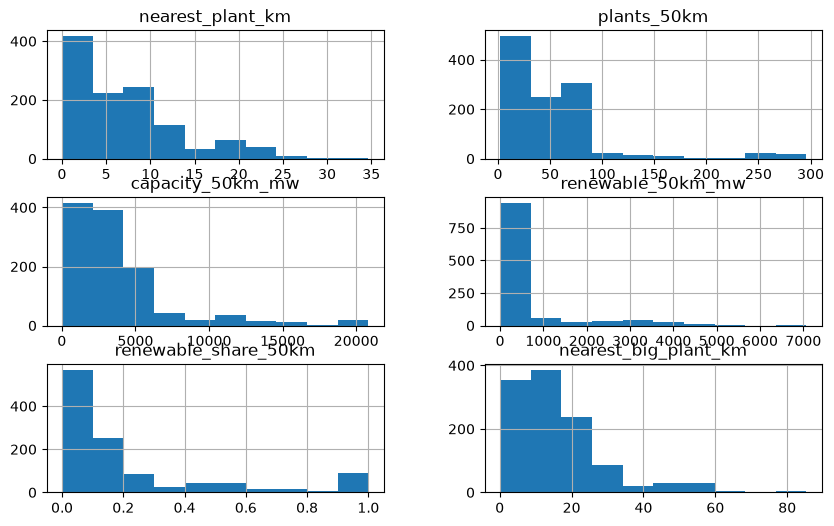

In [19]:
print(eia_features.skew(numeric_only=True))
eia_features.hist(figsize=(10, 6))